# 05 · The one-time test (Phase 2)

**Purpose.** Every model and setting so far was chosen on 2020–2024. 2024 served as the clean check, but it was used to judge two decisions (adopting model (b) in notebook 03b, keeping the text score in notebook 04), so its numbers are slightly optimistic. The **test period, January 2025 to October 2026** (22 months, about 11,200 routine inspections), has never been scored. This notebook scores it **once**, with models fixed in advance, and then asks what the result means: impact in days and violations, and whether the ranking treats neighbourhoods fairly.

**Pre-declared before scoring (PLAN.md, decision log 2026-11-11)**

| | |
|---|---|
| **Primary model** | Model (b) + TF-IDF text score: model (b)'s 33 features plus the logit of a TF-IDF text score (2 routine cycles of earlier comments, words and word pairs, C = 0.3) as a 34th input, logistic regression C = 0.003 |
| **Secondary model** | Model (b) alone (33 features) |
| **Comparators** | Today's order · Rule 1 (previous inspection had a Priority violation or failed) · perfect hindsight |
| **Training** | All 2020–2024 rows (train + validation). Text scores on training rows are out-of-fold (5 groups by establishment) |
| **Scoring** | One fit, scored on all 22 test months. Scores use only data from before the first day of each visit's month |
| **Headline** | Share of first-half-of-month visits that find a Priority violation (HR@50), with 95% CIs from resampling months |
| **Exit bar** | Primary beats Rule 1 by **≥ 3 hits per 100 first-half visits, with a CI excluding zero** |
| **Text verdict** | Primary vs secondary on the headline, with its CI |

Nothing below changes a model, a setting or a metric after the test period is scored. Analyses after §3 describe the result; none feeds back into the models.

## 0 · Setup

In [1]:
import json
import warnings
from collections import Counter
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import average_precision_score, brier_score_loss
from sklearn.neighbors import BallTree

from inspections import config, features, text
from inspections.checks import CheckLog
from inspections.metrics import bootstrap_diff, capture_curve, days_earlier, first_half, hit_rate, per_month
from inspections.models import MODEL_C, N_CYCLES, TFIDF_C, fit_and_score, make_logreg
from inspections.text import EMAIL, PHONE, text_windows

warnings.filterwarnings('ignore', message='This pattern is interpreted as a regular expression')
pd.set_option('display.width', 160)

visits = pd.read_parquet(config.PROCESSED / 'visits.parquet')
violations = pd.read_parquet(config.PROCESSED / 'violations.parquet')
licenses = pd.read_parquet(config.PROCESSED / 'licenses.parquet')
manifest = json.loads((config.RAW / 'manifest.json').read_text())
print(f'{len(visits):,} visits · {len(violations):,} violation rows · scikit-learn {sklearn.__version__}')
print(f'inspection snapshot: {manifest["inspections"]["file"]}')

193,852 visits · 835,847 violation rows · scikit-learn 1.9.1
inspection snapshot: food_inspections_20261110.csv


**From the package (`src/inspections/`):** the metric helpers, the `check()` helper, model (b)'s feature builder, the comment cleaning, the text windows and the two pre-declared models (`MODEL_C` = 0.003, `TFIDF_C` = 0.3, `N_CYCLES` = 2). §2 proves the pipeline reproduces notebook 04's 2024 results exactly.

In [2]:
CHECKS = CheckLog()
check = CHECKS.check

In [3]:
viol_groups = features.violation_group_counts(violations)

## 1 · Rows, features and text for 2020–2026

All rows of the prediction set, including the test period, get model (b)'s features and their comment text **as of the first day of the visit's month (t0)**. Building features for test rows is safe: every feature and every comment comes from before t0. What must not happen is any *label* from the test period reaching a model, which §2–§3 guard.

In [4]:
rows = visits[visits.in_prediction_set & visits.split.isin(['train', 'valid', 'test'])].copy()
y = rows.hit.to_numpy()
year = rows.visit_ts.dt.year.to_numpy()
split = rows.split.to_numpy()
lic = rows.licenseno.to_numpy()
keys = features.decision_keys(rows)
is_test = split == 'test'
check('R14', 'the test period is January 2025 to October 2026, 22 months',
      rows.loc[is_test, 'month'].min() == '2025-01' and rows.loc[is_test, 'month'].max() == '2026-10'
      and rows.loc[is_test, 'month'].nunique() == 22, f'{is_test.sum():,} test rows · {(~is_test).sum():,} rows 2020–2024')

X_b = features.build_model_b(keys, visits, viol_groups, licenses)

com = text.clean_comments(violations)
W = text_windows(keys, visits, com, N_CYCLES)
TEXT = W.comments.map(' '.join)

check('P1', 'model (b) has its 33 features', X_b.shape[1] == 33)
has = W.latest_ts.notna()
check('R15', 'test-period text comes only from visits before t0', (W.latest_ts[has] < keys.t0[has]).all(),
      f'{has[is_test].mean():.0%} of test rows have text')
check('R18', 'no email addresses or phone numbers in the text', not TEXT.str.contains(EMAIL).any() and not TEXT.str.contains(PHONE).any())

✓ R14: the test period is January 2025 to October 2026, 22 months  [11,198 test rows · 27,457 rows 2020–2024]


✓ P1: model (b) has its 33 features
✓ R15: test-period text comes only from visits before t0  [72% of test rows have text]


✓ R18: no email addresses or phone numbers in the text


**Truncation test on the test period (R14, R15, R25).** Delete every visit and comment from 1 July 2025 onward and rebuild the features and text. Every row decided before that date must get identical inputs.

In [5]:
CUT = pd.Timestamp('2025-07-01')
early = keys.t0 < CUT
v_cut = visits[visits.visit_ts.dt.tz_localize(None) < CUT]
X_cut = features.build_model_b(keys[early], v_cut, viol_groups, licenses)
T_cut = text_windows(keys[early], v_cut, com[com.ts < CUT], N_CYCLES).comments.map(' '.join)
same_x = np.isclose(X_cut.to_numpy(), X_b[early].to_numpy(), equal_nan=True).all(axis=1)
same_t = (T_cut == TEXT[early]).to_numpy()
check('R25', 'features and text unchanged when all data from July 2025 on is deleted', same_x.all() and same_t.all(),
      f'{early.sum():,} rows ({(early & is_test).sum():,} in the test period), {(~same_x).sum()} feature and {(~same_t).sum()} text mismatches')

✓ R25: features and text unchanged when all data from July 2025 on is deleted  [30,569 rows (3,112 in the test period), 0 feature and 0 text mismatches]


**Are the last test months fully recorded?** The snapshot was taken on 10 November 2026. If violations from late October were still being entered, the last month would show too few hits. Two signs are checked: every test visit has a recorded result, and the last month's hit rate lies within the range of the other 21 months.

In [6]:
monthly = rows[is_test].groupby('month').hit.mean()
check('R12', 'every test visit has a recorded result', rows.loc[is_test, 'role'].notna().all())
check('R12', "the last test month's hit rate lies within the other months' range",
      monthly.iloc[:-1].min() <= monthly.iloc[-1] <= monthly.iloc[:-1].max(),
      f'Oct 2026: {monthly.iloc[-1]:.1%}; other months {monthly.iloc[:-1].min():.1%}–{monthly.iloc[:-1].max():.1%}')

✓ R12: every test visit has a recorded result
✓ R12: the last test month's hit rate lies within the other months' range  [Oct 2026: 20.5%; other months 16.3%–30.7%]


## 2 · The final pipeline, and a dress rehearsal on 2024

`final_models(train, score)` fits both pre-declared models on the `train` rows and scores the `score` rows:
1. **Text score on training rows, out-of-fold:** 5 groups by establishment, each scored by a TF-IDF model fit on the other four.
2. **Text score on scored rows:** a TF-IDF model fit on all training rows.
3. **Secondary:** model (b) fit on the training rows. **Primary:** model (b) plus the text score's logit, fit on the training rows.

**Dress rehearsal.** Run with training rows 2020–2023 and scored rows 2024, the pipeline must reproduce notebook 04's logged 2024 results **exactly**. That proves the code that will score the test period is the code that was validated.

In [7]:
def final_models(train, score):
    """Fit the pre-declared primary and secondary models on `train` rows; return their scores on `score` rows."""
    return fit_and_score(X_b, y, train, score, text=TEXT, groups=lic).rename(columns={'with_text': 'primary'})

def eval_frame(score_mask, scores, seed=config.SEED):
    """The scored rows with every method's ranking score, as in notebooks 02–04."""
    e = rows.loc[score_mask, ['month', 'visit_ts', 'hit', 'category', 'licenseno']].copy()
    e['tiebreak'] = np.random.default_rng(seed).random(len(e))
    e['actual'] = -e.visit_ts.dt.tz_localize(None).astype('int64')
    e['oracle'] = e.hit.astype(int)
    Xe = X_b.loc[e.index]
    e['rule1'] = features.rule1_score(Xe)
    return e.join(scores)

rehearsal = eval_frame(year == 2024, final_models(year < 2024, year == 2024))
logged = pd.read_csv(config.RESULTS / 'experiments.csv')
nb04 = logged[(logged.notebook == '04_text_models') & (logged.note == 'final check on 2024 (clean)')].set_index('experiment')
hr = {k: hit_rate(per_month(rehearsal, k)) for k in ['model_b', 'primary']}
ap = average_precision_score(rehearsal.hit, rehearsal.primary)
check('R23', 'rehearsal reproduces notebook 04: model (b), 2024 first-half hit rate', abs(hr['model_b'] - nb04.loc['Model (b)', 'HR@50']) < 1e-12,
      f'{hr["model_b"]:.4f}')
primary_row = nb04.loc[nb04.index.str.startswith('Model (b) + text')].iloc[0]
check('R23', 'rehearsal reproduces notebook 04: model (b) + text, 2024 first-half hit rate and PR-AUC',
      abs(hr['primary'] - primary_row['HR@50']) < 1e-12 and abs(ap - primary_row['PR-AUC']) < 1e-9, f'{hr["primary"]:.4f} · PR-AUC {ap:.4f}')

✓ R23: rehearsal reproduces notebook 04: model (b), 2024 first-half hit rate  [0.3480]
✓ R23: rehearsal reproduces notebook 04: model (b) + text, 2024 first-half hit rate and PR-AUC  [0.3484 · PR-AUC 0.4317]


## 3 · The test: train on 2020–2024, score January 2025 to October 2026 (once)

In [8]:
train, test = year <= 2024, is_test
check('R14', 'no test-period label is used for training', not is_test[train].any() and train.sum() == (~is_test).sum(),
      f'{train.sum():,} training rows (2020–2024)')
te = eval_frame(test, final_models(train, test))
print(f'scored {len(te):,} test rows from {te.month.min()} to {te.month.max()} ({te.month.nunique()} months)')

✓ R14: no test-period label is used for training  [27,457 training rows (2020–2024)]


scored 11,198 test rows from 2025-01 to 2026-10 (22 months)


In [9]:
METHODS = [('actual', "Today's order"), ('rule1', 'Rule 1 · previous inspection'), ('model_b', 'Model (b) · secondary'),
           ('primary', 'Model (b) + text · primary'), ('oracle', 'Perfect hindsight')]

def compare(e, methods=METHODS):
    pm = {k: per_month(e, k) for k, _ in methods}
    base, orc, r1, mb = (hit_rate(pm[k]) for k in ['actual', 'oracle', 'rule1', 'model_b'])
    out = {}
    for k, name in methods:
        h = hit_rate(pm[k])
        lo1, hi1 = bootstrap_diff(pm[k], pm['rule1'])
        lob, hib = bootstrap_diff(pm[k], pm['model_b'])
        out[name] = {'HR@50': h, 'vs Rule 1 (per 100)': 100 * (h - r1),
                     'vs Rule 1 95% CI': '—' if k == 'rule1' else f'[{100 * lo1:+.1f}, {100 * hi1:+.1f}]',
                     'vs model (b) (per 100)': 100 * (h - mb),
                     'vs model (b) 95% CI': '—' if k == 'model_b' else f'[{100 * lob:+.1f}, {100 * hib:+.1f}]',
                     'headroom captured': (h - base) / (orc - base), 'days earlier': days_earlier(e, k),
                     'PR-AUC': average_precision_score(e.hit, e[k])}
    return pd.DataFrame(out).T

FMT = {'HR@50': '{:.1%}', 'vs Rule 1 (per 100)': '{:+.1f}', 'vs model (b) (per 100)': '{:+.1f}', 'headroom captured': '{:.0%}',
       'days earlier': '{:.1f}', 'PR-AUC': '{:.3f}'}
result = compare(te)
result.style.format(FMT)

,HR@50,vs Rule 1 (per 100),vs Rule 1 95% CI,vs model (b) (per 100),vs model (b) 95% CI,headroom captured,days earlier,PR-AUC
Today's order,23.2%,-7.1,"[-8.7, -5.3]",-9.8,"[-11.3, -8.2]",0%,0.0,0.204
Rule 1 · previous inspection,30.3%,+0.0,—,-2.8,"[-3.4, -2.2]",33%,3.0,0.330
Model (b) · secondary,33.0%,+2.8,"[+2.2, +3.4]",+0.0,—,46%,4.8,0.413
Model (b) + text · primary,33.3%,+3.0,"[+2.3, +3.7]",+0.3,"[-0.1, +0.7]",47%,4.9,0.420
Perfect hindsight,44.7%,+14.4,"[+12.4, +16.4]",+11.7,"[+9.8, +13.5]",100%,11.2,1.000


In [10]:
pm = {k: per_month(te, k) for k in ['rule1', 'model_b', 'primary']}
gain_r1 = 100 * (hit_rate(pm['primary']) - hit_rate(pm['rule1']))
lo_r1, hi_r1 = 100 * bootstrap_diff(pm['primary'], pm['rule1'])
gain_b = 100 * (hit_rate(pm['primary']) - hit_rate(pm['model_b']))
lo_b, hi_b = 100 * bootstrap_diff(pm['primary'], pm['model_b'])
lo_s, hi_s = 100 * bootstrap_diff(pm['model_b'], pm['rule1'])
verdicts = pd.Series({
    'Exit bar: primary ≥ +3 vs Rule 1, CI excluding zero': f'{"MET" if gain_r1 >= 3 and lo_r1 > 0 else "NOT MET"} '
                                                          f'(+{gain_r1:.1f} [{lo_r1:+.1f}, {hi_r1:+.1f}])',
    'Machine learning beats Rule 1 (CI excluding zero)': f'primary {"yes" if lo_r1 > 0 else "no"}; secondary {"yes" if lo_s > 0 else "no"} '
                                                        f'([{lo_s:+.1f}, {hi_s:+.1f}])',
    'Text verdict: primary vs secondary': f'{gain_b:+.1f} per 100 [{lo_b:+.1f}, {hi_b:+.1f}] → '
                                          + ('text helps' if lo_b > 0 else 'text hurts' if hi_b < 0 else 'no detectable difference'),
}, name='pre-declared verdict')
verdicts.to_frame()

,pre-declared verdict
"Exit bar: primary ≥ +3 vs Rule 1, CI excluding zero","MET (+3.0 [+2.3, +3.7])"
Machine learning beats Rule 1 (CI excluding zero),"primary yes; secondary yes ([+2.2, +3.4])"
Text verdict: primary vs secondary,"+0.3 per 100 [-0.1, +0.7] → no detectable diff..."


**By year and by licence type.** The test period spans two calendar years; the model was trained once, at the end of 2024, so 2026 is further from the training data. Licence types: FS sit-down restaurants, FT take-out restaurants, RF retail food stores.

In [11]:
parts = {'2025': te[te.visit_ts.dt.year == 2025], '2026 (Jan–Oct)': te[te.visit_ts.dt.year == 2026]}
parts |= {f'licence type {c}': te[te.category == c] for c in ['FS', 'FT', 'RF']}
sub = []
for name, e in parts.items():
    if e.empty:
        continue
    p = {k: per_month(e, k) for k in ['actual', 'rule1', 'model_b', 'primary']}
    lo, hi = bootstrap_diff(p['primary'], p['rule1'])
    sub.append({'part': name, 'visits': len(e), 'hit rate': e.hit.mean(), "today's order": hit_rate(p['actual']),
                'Rule 1': hit_rate(p['rule1']), 'model (b)': hit_rate(p['model_b']), 'model (b) + text': hit_rate(p['primary']),
                'primary vs Rule 1, per 100': 100 * (hit_rate(p['primary']) - hit_rate(p['rule1'])), '95% CI': f'[{100 * lo:+.1f}, {100 * hi:+.1f}]'})
sub = pd.DataFrame(sub).set_index('part')
sub.style.format({'visits': '{:,.0f}', 'hit rate': '{:.1%}', "today's order": '{:.1%}', 'Rule 1': '{:.1%}', 'model (b)': '{:.1%}',
                  'model (b) + text': '{:.1%}', 'primary vs Rule 1, per 100': '{:+.1f}'})

,visits,hit rate,today's order,Rule 1,model (b),model (b) + text,"primary vs Rule 1, per 100",95% CI
part,,,,,,,,
2025,"6,216",20.1%,20.4%,28.7%,31.5%,31.3%,+2.6,"[+1.6, +3.4]"
2026 (Jan–Oct),"4,982",25.2%,26.7%,32.3%,35.0%,35.9%,+3.5,"[+2.7, +4.5]"
licence type FS,"4,975",27.0%,27.6%,34.6%,37.4%,38.1%,+3.5,"[+2.6, +4.5]"
licence type FT,"4,731",20.5%,21.1%,27.9%,30.8%,31.1%,+3.1,"[+1.7, +4.7]"
licence type RF,"1,492",12.7%,13.0%,17.7%,19.6%,20.5%,+2.8,"[+1.5, +4.4]"


**Reading the test.**
- **The exit bar is met, at the threshold.** The primary model finds a Priority violation in 33.3% of first-half visits against 30.3% for Rule 1: **+3.0 per 100 visits [+2.3, +3.7]** (+3.02 before rounding). The CI excludes zero, so the pre-declared bar is met. The interval also reaches below +3, so the accurate summary is "about +3 per 100", not "clearly above the bar". Model (b) alone gives +2.8 [+2.2, +3.4], just short.
- **The result holds up on unseen data.** Both models beat Rule 1 with CIs excluding zero and beat today's order by about 10 points. The gain is in line with the 2024 check (+2.5 and +2.4) and slightly larger. The model captures 47% of the gap between today's order and perfect hindsight; Rule 1 captures 33%.
- **The text adds nothing detectable:** +0.3 per 100 over model (b) [−0.1, +0.7]. The direction matches every earlier year, and PR-AUC rises from 0.413 to 0.420.
- **It holds in both years and for every licence type,** each with a CI excluding zero: 2025 +2.6, 2026 +3.5; sit-down +3.5, take-out +3.1, retail +2.8. The 2026 hit rate rose to 25% (2025: 20%), and the gain grew rather than shrank, even though 2026 is furthest from the training data.

## 4 · Where in the month the gain appears, and with two-week lists (P12)

**Capture curve:** the share of each month's hits found after the first 5%, 10%, 25% and 50% of the month's visits.

**Two-week replay (as in notebook 03b §8):** each month is split into days 1–15 and 16–end, and visits are re-ranked within each block, so no visit moves more than two weeks. Scores are still computed at the start of the month.

In [12]:
cuts = [0.05, 0.10, 0.25, 0.50]
cap = pd.DataFrame({name: [per_month(te, k, q).hits.sum() / per_month(te, k, q).month_hits.sum() for q in cuts] for k, name in METHODS},
                   index=[f'first {q:.0%} of visits' for q in cuts])
cap.style.format('{:.1%}')

,Today's order,Rule 1 · previous inspection,Model (b) · secondary,Model (b) + text · primary,Perfect hindsight
first 5% of visits,5.0%,8.5%,12.1%,12.7%,22.0%
first 10% of visits,9.7%,17.1%,23.0%,23.1%,44.4%
first 25% of visits,25.1%,40.3%,46.6%,46.9%,97.0%
first 50% of visits,51.9%,67.8%,73.9%,74.5%,100.0%


In [13]:
te['period_2wk'] = te['month'] + np.where(te.visit_ts.dt.day <= 15, '·a', '·b')
replay = compare(te.assign(month=te.period_2wk))
replay.style.format(FMT)

,HR@50,vs Rule 1 (per 100),vs Rule 1 95% CI,vs model (b) (per 100),vs model (b) 95% CI,headroom captured,days earlier,PR-AUC
Today's order,22.0%,-8.1,"[-9.4, -6.8]",-11.1,"[-12.5, -9.7]",0%,0.0,0.204
Rule 1 · previous inspection,30.1%,+0.0,—,-3.0,"[-3.8, -2.3]",36%,1.7,0.330
Model (b) · secondary,33.1%,+3.0,"[+2.3, +3.8]",+0.0,—,49%,2.5,0.413
Model (b) + text · primary,33.3%,+3.2,"[+2.4, +4.0]",+0.2,"[-0.1, +0.5]",49%,2.5,0.420
Perfect hindsight,44.8%,+14.7,"[+13.0, +16.3]",+11.7,"[+10.2, +13.2]",100%,5.6,1.000


**Reading §4.**
- **The model leads Rule 1 at every point of the month.** In the first 10% of visits it finds 23.1% of the month's hits (Rule 1 17.1%, today 9.7%); by the halfway point, 74.5% (Rule 1 67.8%, today 51.9%).
- **The text model differs from model (b) by under a point anywhere on the curve,** as in 2024.
- **Two-week lists keep the gain:** +3.2 per 100 over Rule 1 [+2.4, +4.0], with a similar share of the headroom (49% vs 47% monthly). "Days earlier" halves (4.9 → 2.5) because no visit can move more than two weeks. The per-visit lift does not depend on month-long stability.

## 5 · Calibration on the test period (R12)

The ranking only needs the *order* of scores within a month. A risk score shown to inspectors as a probability also needs to be **calibrated**: of the visits given 30%, about 30% should find a Priority violation. The test period is the first data the model has not seen at all, and the base rate drifts between years.

In [14]:
cal = {}
for k, name in [('model_b', 'model (b)'), ('primary', 'model (b) + text')]:
    cal[name] = {'Brier score': brier_score_loss(te.hit, te[k]), 'mean predicted': te[k].mean(), 'observed hit rate': te.hit.mean()}
    for yy in [2025, 2026]:
        m = te.visit_ts.dt.year == yy
        cal[name][f'{yy}: predicted − observed (points)'] = 100 * (te.loc[m, k].mean() - te.hit[m].mean())
cal['constant (overall rate)'] = {'Brier score': brier_score_loss(te.hit, np.full(len(te), te.hit.mean()))}
pd.DataFrame(cal).T.style.format({'Brier score': '{:.4f}', 'mean predicted': '{:.1%}', 'observed hit rate': '{:.1%}',
                                  '2025: predicted − observed (points)': '{:+.1f}', '2026: predicted − observed (points)': '{:+.1f}'}, na_rep='')

,Brier score,mean predicted,observed hit rate,2025: predicted − observed (points),2026: predicted − observed (points)
model (b),0.1564,20.4%,22.3%,-0.1,-4.2
model (b) + text,0.1554,20.5%,22.3%,-0.1,-4.0
constant (overall rate),0.1735,,,,


In [15]:
band = pd.qcut(te.primary, 10, labels=False) + 1
rel = te.groupby(band).agg(visits=('hit', 'size'), predicted=('primary', 'mean'), observed=('hit', 'mean')).rename_axis('score tenth (1 = lowest)')
rel['observed − predicted (points)'] = 100 * (rel.observed - rel.predicted)
rel.T.style.format('{:.2f}')

score tenth (1 = lowest),1,2,3,4,5,6,7,8,9,10
visits,1120.00,1120.00,1120.00,1119.00,1120.00,1120.00,1119.00,1120.00,1120.00,1120.00
predicted,0.05,0.08,0.09,0.11,0.14,0.17,0.22,0.27,0.37,0.55
observed,0.05,0.09,0.14,0.13,0.15,0.22,0.26,0.30,0.39,0.51
observed − predicted (points),0.30,1.19,4.23,1.44,1.73,4.89,4.06,2.32,2.00,-3.97


**Reading §5.**
- **2025 is well calibrated** (average prediction within 0.1 points of the observed rate). **2026 is under-predicted by about 4 points:** the observed rate rose to 25% and a model fit on 2020–2024 did not anticipate it. Both models beat a constant prediction on the Brier score (0.155 vs 0.174).
- **The ranking is unaffected.** A shift in the base rate moves every score in a month alike, and the gain over Rule 1 was larger in 2026.
- **By score tenth,** the middle bands are under-predicted by 1–5 points and the top tenth over-predicted by 4.
- **Implication:** for ranking alone, no recalibration is needed. If scores are shown to inspectors as probabilities, refit the model (or at least its intercept) each year.

## 6 · Impact: what the ranking would have changed in 2025–26

The same visits, the same inspectors, the same month; only the order changes. Two measures per year (the 22 test months scaled to 12):
- **Priority violations found in the first half of the month instead of the second**, relative to today's order and to Rule 1.
- **Days earlier:** how much sooner, on average, a visit that finds a Priority violation happens. Multiplied by the number of such visits, this gives **violation-days avoided**: days a hazard would have stayed open, *assuming it was already present at the start of the month* and is corrected when found.

In [16]:
per_year = 12 / te.month.nunique()
n_hits = te.hit.sum()
imp = {}
for k, name in METHODS:
    p = per_month(te, k)
    d = days_earlier(te, k)
    imp[name] = {'Priority violations found in the first half, per year': p.hits.sum() * per_year,
                 'vs today, per year': (p.hits.sum() - per_month(te, 'actual').hits.sum()) * per_year,
                 'vs Rule 1, per year': (p.hits.sum() - per_month(te, 'rule1').hits.sum()) * per_year,
                 'days earlier, per violation': d,
                 'violation-days avoided, per year': d * n_hits * per_year}
impact = pd.DataFrame(imp).T
print(f'per year: {len(te) * per_year:,.0f} routine inspections, {n_hits * per_year:,.0f} of them find a Priority violation')
impact.style.format({c: '{:,.0f}' for c in impact.columns} | {'days earlier, per violation': '{:.1f}'} | {'vs today, per year': '{:+,.0f}', 'vs Rule 1, per year': '{:+,.0f}'})

per year: 6,108 routine inspections, 1,364 of them find a Priority violation


,"Priority violations found in the first half, per year","vs today, per year","vs Rule 1, per year","days earlier, per violation","violation-days avoided, per year"
Today's order,709,+0,-216,0.0,0
Rule 1 · previous inspection,925,+216,+0,3.0,"4,142"
Model (b) · secondary,"1,009",+300,+84,4.8,"6,533"
Model (b) + text · primary,"1,017",+308,+92,4.9,"6,682"
Perfect hindsight,"1,364",+656,+440,11.2,"15,263"


**Reading §6.**
- **Scale.** About 6,100 routine inspections a year, of which about 1,360 find a Priority violation. Today's order reaches about 710 of those in the first half of the month, close to half, as chance would.
- **With the model's order, about 1,020 are found in the first half:** roughly **300 more a year than today** and **about 90 more than Rule 1**.
- **Each of those violations is found 4.9 days sooner on average** (Rule 1: 3.0). That is about **6,700 violation-days avoided a year**, against 4,100 for Rule 1. Rule 1 alone, with no machine learning, delivers about 70% of the model's extra early finds and 60% of its violation-days.
- **What these numbers assume:**
  - a hazard found later was already present at the start of the month;
  - inspectors can follow the order;
  - visits move only within the month.

  With two-week lists, the days gained halve.

## 7 · Fairness by neighbourhood and income (P11)

Model (b) uses how strict recent inspections have been within 1 km, which partly reflects *which inspector* covers an area (TECHNICAL.md §8). A ranking built on it could move visits toward some neighbourhoods for reasons unrelated to their kitchens. Visits are never added or removed, only reordered within the month, so the question is **whose hazards are found earlier, and whose later**.

**Areas.**
- **Neighbourhood:** each establishment takes the most common neighbourhood among its 25 nearest 311 cases (the city's own neighbourhood labels; the generic label "Boston" is ignored). Establishments without coordinates take the most common neighbourhood of their ZIP code. Neighbourhoods with fewer than 200 test visits are grouped as "smaller areas".
- **Income:** the median household income of the establishment's ZIP code (US Census ACS 2020–2024), split into thirds of test visits. It describes the area, not the business or its customers.

**What is compared, per group** (pre-declared):
1. **Calibration:** observed hit rate vs the primary model's average prediction. A group is flagged if its gap differs from the city-wide gap by more than 5 points (the model rates it differently from everywhere else; a city-wide drift moves every group alike).
2. **Share of the group's visits placed in the first half** by today's order, Rule 1 and the model: who gets visited early.
3. **Share of the group's Priority violations found in the first half:** whose hazards are found early. A group is flagged if the model finds a *smaller* share of its hazards early than today's order does (made worse off than now), with a 95% CI from resampling months; "clear" if the CI excludes zero.
4. **Hit rate among the group's first-half visits:** whether early visits to a group are justified by what they find.

In [17]:
SMALL = 200
MERGE = {'Allston': 'Allston / Brighton', 'Brighton': 'Allston / Brighton', 'South Boston': 'South Boston / South Boston Waterfront',
         'Mattapan': 'Greater Mattapan'}
c311 = pd.read_csv(config.RAW / manifest['311_food_rodent']['file'], usecols=['neighborhood', 'latitude', 'longitude'])
c311 = c311[c311.latitude.between(42.2, 42.45) & c311.longitude.between(-71.2, -70.95)]
c311['area'] = c311.neighborhood.replace(MERGE)
c311 = c311[c311.area.notna() & c311.area.ne('Boston')]
tree = BallTree(np.radians(c311[['latitude', 'longitude']].to_numpy()), metric='haversine')
area_labels = c311.area.to_numpy()

place = licenses[['zip', 'lat', 'lon']].copy()
place['zip5'] = place.zip.str.extract(r'^(\d{4,5})', expand=False).str.zfill(5)
located = place.lat.between(42.2, 42.45) & place.lon.between(-71.2, -70.95)
_, nearest = tree.query(np.radians(place.loc[located, ['lat', 'lon']].to_numpy()), k=25)
place.loc[located, 'neighbourhood'] = [Counter(area_labels[i]).most_common(1)[0][0] for i in nearest]
zip_mode = place[located].groupby('zip5').neighbourhood.agg(lambda s: s.mode().iloc[0])
place.loc[~located, 'neighbourhood'] = place.loc[~located, 'zip5'].map(zip_mode)

census = pd.read_csv(config.RAW / manifest['census_income']['file'], dtype={'zcta': str})
census['income'] = pd.to_numeric(census.median_household_income, errors='coerce').where(lambda s: s > 0)
place['income'] = place.zip5.map(census.set_index('zcta').income)

te = te.join(place[['neighbourhood', 'income']], on='licenseno')
counts = te.neighbourhood.value_counts()
te['neighbourhood'] = te.neighbourhood.where(te.neighbourhood.map(counts).ge(SMALL), 'smaller areas').fillna('smaller areas')
te['income third'] = pd.qcut(te.income, 3, labels=['lower-income third', 'middle third', 'higher-income third'])
edges = te.groupby('income third', observed=True).income.agg(['min', 'max'])
print(f'test visits with a neighbourhood: {te.neighbourhood.ne("smaller areas").mean():.1%} named · with ZIP income: {te.income.notna().mean():.1%}')
print('income thirds (ZIP median household income):', '; '.join(f'{k}: ${r["min"]:,.0f}–${r["max"]:,.0f}' for k, r in edges.iterrows()))

test visits with a neighbourhood: 96.6% named · with ZIP income: 99.5%
income thirds (ZIP median household income): lower-income third: $43,136–$86,150; middle third: $87,404–$126,496; higher-income third: $131,551–$212,928


In [18]:
FH = {k: first_half(te, k) for k in ['actual', 'rule1', 'primary', 'oracle']}

CITY_GAP = 100 * (te.hit.mean() - te.primary.mean())

def early_gap_ci(e, a='primary', b='actual', n=2000, seed=config.SEED):
    """95% CI for (share of the group's hits found in the first half by a) − (same by b), resampling months."""
    m = pd.DataFrame({'month': e.month, 'a': FH[a][e.index] & e.hit, 'b': FH[b][e.index] & e.hit, 'h': e.hit}).groupby('month').sum()
    idx = np.random.default_rng(seed).integers(0, len(m), size=(n, len(m)))
    A, B, H = m.a.to_numpy(), m.b.to_numpy(), m.h.to_numpy()
    return np.percentile((A[idx].sum(1) - B[idx].sum(1)) / H[idx].sum(1), [2.5, 97.5])

def fairness_table(by):
    out = {}
    for g, e in te.groupby(by, observed=True):
        i = e.index
        hits = e.hit
        row = {'visits': len(e), 'hit rate': hits.mean(), 'model predicts': e.primary.mean(),
               'calibration gap (points)': 100 * (hits.mean() - e.primary.mean())}
        for k, name in [('actual', 'today'), ('rule1', 'Rule 1'), ('primary', 'model')]:
            row[f'early visits · {name}'] = FH[k][i].mean()
        for k, name in [('actual', 'today'), ('rule1', 'Rule 1'), ('primary', 'model')]:
            row[f'hazards found early · {name}'] = FH[k][i][hits].mean()
        lo, hi = early_gap_ci(e)
        row['hazards found early · model − today (points)'] = 100 * (row['hazards found early · model'] - row['hazards found early · today'])
        row['95% CI'] = f'[{100 * lo:+.0f}, {100 * hi:+.0f}]'
        row['hit rate of early visits · model'] = hits[FH['primary'][i]].mean()
        worse = row['hazards found early · model'] < row['hazards found early · today']
        row['flag'] = ', '.join(f for f, bad in [('calibration', abs(row['calibration gap (points)'] - CITY_GAP) > 5),
                                                  ('worse than today' + (' (clear)' if hi < 0 else ' (within noise)'), worse)] if bad)
        out[g] = row
    t = pd.DataFrame(out).T
    return t.sort_values('hit rate', ascending=False) if by == 'neighbourhood' else t

print(f'city-wide calibration gap (observed − predicted): {CITY_GAP:+.1f} points')
FAIR_FMT = {'visits': '{:,.0f}', 'hit rate': '{:.0%}', 'model predicts': '{:.0%}', 'calibration gap (points)': '{:+.1f}',
            'hazards found early · model − today (points)': '{:+.0f}',
            'hit rate of early visits · model': '{:.0%}'} | {c: '{:.0%}' for c in
            [f'{a} · {b}' for a in ['early visits', 'hazards found early'] for b in ['today', 'Rule 1', 'model']]}
fair_n = fairness_table('neighbourhood')
fair_n.style.format(FAIR_FMT)

city-wide calibration gap (observed − predicted): +1.8 points


,visits,hit rate,model predicts,calibration gap (points),early visits · today,early visits · Rule 1,early visits · model,hazards found early · today,hazards found early · Rule 1,hazards found early · model,hazards found early · model − today (points),95% CI,hit rate of early visits · model,flag
Mission Hill,228,26%,27%,-0.7,55%,59%,66%,52%,72%,88%,+37,"[+20, +52]",35%,
Greater Mattapan,232,26%,26%,+0.8,48%,62%,58%,49%,77%,84%,+34,"[+21, +49]",38%,
Back Bay,888,26%,21%,+4.4,51%,51%,56%,51%,60%,69%,+18,"[+8, +27]",32%,
Jamaica Plain,412,26%,29%,-3.4,50%,64%,72%,58%,74%,87%,+29,"[+20, +39]",31%,calibration
Allston / Brighton,"1,099",25%,25%,+0.0,50%,48%,57%,48%,74%,85%,+36,"[+27, +47]",37%,
Roxbury,619,25%,25%,-0.7,54%,60%,64%,60%,80%,88%,+27,"[+16, +37]",34%,
smaller areas,382,24%,20%,+4.3,52%,53%,51%,52%,71%,73%,+22,"[+6, +36]",35%,
South End,286,24%,25%,-0.6,56%,63%,71%,58%,80%,84%,+26,"[+14, +39]",29%,
Downtown / Financial District,"2,348",23%,19%,+4.6,49%,45%,42%,51%,61%,67%,+16,"[+9, +24]",37%,
Roslindale,255,22%,23%,-0.2,48%,58%,55%,54%,72%,77%,+23,"[+4, +44]",31%,


In [19]:
fair_i = fairness_table('income third')
fair_i.style.format(FAIR_FMT)

,visits,hit rate,model predicts,calibration gap (points),early visits · today,early visits · Rule 1,early visits · model,hazards found early · today,hazards found early · Rule 1,hazards found early · model,hazards found early · model − today (points),95% CI,hit rate of early visits · model,flag
lower-income third,"3,714",24%,24%,+0.1,49%,56%,60%,49%,73%,83%,+34,"[+29, +40]",33%,
middle third,"3,780",23%,21%,+2.5,51%,51%,51%,52%,68%,75%,+23,"[+19, +29]",34%,
higher-income third,"3,643",20%,17%,+2.9,50%,43%,38%,56%,61%,63%,+7,"[+1, +13]",32%,


**How much of the pattern comes from local strictness?** A diagnostic only, not a candidate model: model (b) refit on 2020–2024 **without its six area features**, scored on the test period. Comparing where it places early visits shows how much the local-strictness inputs move visits between areas, and what they contribute to the headline.

In [20]:
AREA_COLS = [c for c in X_b.columns if c.startswith('area_')]
no_area = make_logreg().fit(X_b.loc[train].drop(columns=AREA_COLS), y[train]).predict_proba(X_b.loc[test].drop(columns=AREA_COLS))[:, 1]
te['no_area'] = pd.Series(no_area, index=rows.index[test]).loc[te.index]
FH['no_area'] = first_half(te, 'no_area')
pm_na = per_month(te, 'no_area')
lo, hi = bootstrap_diff(pm_na, per_month(te, 'model_b'))
print(f'model (b) without area features: first-half hit rate {hit_rate(pm_na):.1%} '
      f'({100 * (hit_rate(pm_na) - hit_rate(per_month(te, "model_b"))):+.1f} per 100 vs model (b) [{100 * lo:+.1f}, {100 * hi:+.1f}])')
strict = pd.DataFrame({by: {g: {'early visits · model': FH['primary'][e.index].mean(), 'early visits · without area features': FH['no_area'][e.index].mean(),
                                'hazards found early · model': FH['primary'][e.index][e.hit].mean(),
                                'hazards found early · without area features': FH['no_area'][e.index][e.hit].mean()}
                            for g, e in te.groupby(by, observed=True)} for by in ['income third']}['income third']).T
strict.style.format('{:.0%}')

model (b) without area features: first-half hit rate 32.7% (-0.4 per 100 vs model (b) [-0.9, +0.3])


,early visits · model,early visits · without area features,hazards found early · model,hazards found early · without area features
lower-income third,60%,59%,83%,81%
middle third,51%,51%,75%,74%
higher-income third,38%,40%,63%,63%


**Reading §7.**
- **No neighbourhood or income group is clearly worse off than today.** In 14 of 16 neighbourhood groups, the model finds a larger share of the group's Priority violations in the first half than today's order does, with a CI excluding zero (+16 to +39 points). The two exceptions:
  - **South Boston** shows no change (+1 [−9, +12]).
  - **Charlestown,** the area with the lowest hit rate (12%), shows −23 points [−40, +6]. That is within noise, but the direction is expected: reordering moves early visits away from areas with few hazards, so those few are found somewhat later.
- **Gains follow the risk, so they are uneven.**
  - **Lower-income third (by ZIP):** 60% of visits move into the first half, and 83% of hazards are found early (+34 points vs today).
  - **Higher-income third:** 38% of visits and 63% of hazards (+7 [+1, +13]).
  - **Why this is not over-targeting:** the hit rate among early visits is the same in every third (33%, 34%, 32%). Early visits to lower-income areas find hazards as often as early visits elsewhere.
- **Calibration by group is good.** The income thirds are within 1.7 points of the city-wide gap. Only Jamaica Plain is flagged: it is over-predicted by 5.2 points relative to the city.
- **Local strictness is not what moves visits between areas.** Without the six area features, the split of early visits by income third is almost unchanged (59/51/40% vs 60/51/38%), and the headline changes by −0.4 per 100 [−0.9, +0.3]. The tilt comes from establishments' own inspection records. The concern that the area features steer visits by inspector (TECHNICAL.md §8) is small in practice for allocation.
- **Limits.**
  - Neighbourhoods come from the city's 311 labels.
  - Income describes residents of the ZIP code, not the business or its customers.
  - No race or ethnicity analysis was done.
  - This checks fairness of the *order* only, not of who is due or how often.

## 8 · Figure for the README

The front-page chart, now drawn from the **test period** with the primary model: the share of each month's Priority violations found as inspectors work through the month's list. Light and dark versions, as in notebook 03b.

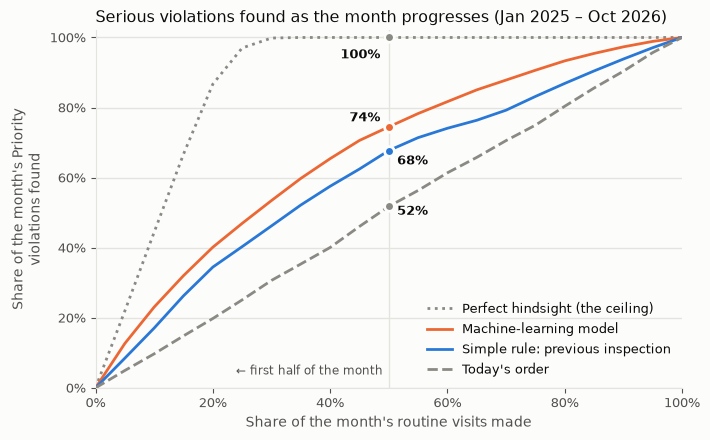

test period: share of the month's hits found by the 50% mark: {'today': '52%', 'rule': '68%', 'model': '74%', 'ceiling': '100%'}


In [21]:
grid = np.linspace(0.05, 1, 20)

README_STYLE = {
    'light': dict(surface='#fcfcfb', ink='#0b0b0b', muted='#52514e', grid='#e4e3df', rule='#2a78d6', model='#eb6834', ref='#8a8984'),
    'dark':  dict(surface='#1a1a19', ink='#f0efec', muted='#c3c2b7', grid='#33332f', rule='#3987e5', model='#d95926', ref='#8f8e88'),
}
x = np.r_[0, 100 * grid]
ys = {key: np.r_[0, 100 * capture_curve(te, col, grid)] for key, col in
      [('today', 'actual'), ('rule', 'rule1'), ('model', 'primary'), ('ceiling', 'oracle')]}
at50 = {k: np.interp(50, x, v) for k, v in ys.items()}

for mode, c in README_STYLE.items():
    fig, ax = plt.subplots(figsize=(7.2, 4.5), facecolor=c['surface'])
    ax.set_facecolor(c['surface'])
    series = [('ceiling', 'Perfect hindsight (the ceiling)', c['ref'], ':'),
              ('model', 'Machine-learning model', c['model'], '-'),
              ('rule', 'Simple rule: previous inspection', c['rule'], '-'),
              ('today', "Today's order", c['ref'], '--')]
    ax.axvline(50, color=c['grid'], lw=1, zorder=0)
    ax.text(49, 3, '← first half of the month', color=c['muted'], fontsize=8.5, va='bottom', ha='right')
    for key, label, color, ls in series:
        ax.plot(x, ys[key], ls, color=color, lw=2, label=label, zorder=3)
        ax.plot(50, at50[key], 'o', ms=7, color=color, mec=c['surface'], mew=2, zorder=4)
    offsets = {'ceiling': (-6, -15), 'model': (-6, 4), 'rule': (6, -10), 'today': (6, -6)}
    for key in ['ceiling', 'model', 'rule', 'today']:
        dx, dy = offsets[key]
        ax.annotate(f'{at50[key]:.0f}%', (50, at50[key]), xytext=(dx, dy), textcoords='offset points',
                    ha='right' if dx < 0 else 'left', color=c['ink'], fontsize=9.5, fontweight='bold')
    ax.set(xlim=(0, 100), ylim=(0, 102))
    ax.set_xlabel("Share of the month's routine visits made", color=c['muted'])
    ax.set_ylabel("Share of the month's Priority\nviolations found", color=c['muted'])
    ax.set_title('Serious violations found as the month progresses (Jan 2025 – Oct 2026)', color=c['ink'], loc='left', fontsize=11.5)
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter())
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter())
    ax.yaxis.grid(True, color=c['grid'], lw=1)
    ax.set_axisbelow(True)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    for side in ['left', 'bottom']:
        ax.spines[side].set_color(c['grid'])
    ax.tick_params(colors=c['muted'], labelsize=9)
    leg = ax.legend(frameon=False, loc='lower right', fontsize=9)
    for label in leg.get_texts():
        label.set_color(c['ink'])
    fig.tight_layout()
    fig.savefig(config.FIGURES / f'readme_capture_curve_test_{mode}.png', dpi=200, facecolor=c['surface'])
    if mode == 'light':
        plt.show()
    plt.close(fig)

print("test period: share of the month's hits found by the 50% mark:", {k: f'{v:.0f}%' for k, v in at50.items()})

## 9 · Findings

| Test period, Jan 2025 – Oct 2026 (11,198 routine inspections) | First-half hit rate | vs Rule 1, per 100 visits | Days earlier |
|---|---|---|---|
| Today's order | 23.2% | −7.1 | — |
| Rule 1 · previous inspection | 30.3% | — | 3.0 |
| Model (b) · secondary | 33.0% | +2.8 [+2.2, +3.4] | 4.8 |
| **Model (b) + text · primary** | **33.3%** | **+3.0 [+2.3, +3.7]** | **4.9** |
| Perfect hindsight | 44.7% | +14.4 | 11.2 |

1. **The project's exit bar is met on the one-time test, at the threshold:** +3.0 per 100 first-half visits over Rule 1, with a CI excluding zero. The honest summary is "about +3", consistent with 2024 (+2.5) and slightly higher.
2. **The ranking generalises.** The gain holds in both years, for every licence type and with two-week lists, and grew in 2026 despite a higher base rate.
3. **The comment text adds nothing detectable** (+0.3 [−0.1, +0.7] over model (b)). Model (b) alone is within noise of the primary model.
4. **Impact:** about 300 more Priority violations a year found in the first half of the month than today (about 90 more than Rule 1), each about 5 days sooner, or about 6,700 violation-days avoided a year. Rule 1 alone delivers about 60–70% of that.
5. **Calibration drifts:** 2026 is under-predicted by about 4 points. That doesn't matter for ranking; it does if scores are shown as probabilities, so refit yearly.
6. **Fairness:** no neighbourhood or income group is clearly worse off than today. Gains are largest in lower-income areas, where hazards are more common, and early visits find hazards at the same rate in every income third. The local-strictness features barely change where early visits go.
7. **Checks passed:** test labels never used for training (R14); inputs strictly before each month (R15, R25, truncation test 0 mismatches); no sign of incomplete recording in the last month (R12); the scoring pipeline reproduces notebook 04 exactly on 2024 (R23).

## 10 · Experiment log

In [22]:
log = result.reset_index(names='experiment')
log['note'] = 'one-time test, Jan 2025 – Oct 2026 (monthly lists)'
rep = replay.reset_index(names='experiment').assign(note='one-time test, two-week lists (P12)')
diag = pd.DataFrame([{'experiment': 'Model (b) without area features (diagnostic)', 'HR@50': hit_rate(pm_na),
                      'vs Rule 1 (per 100)': 100 * (hit_rate(pm_na) - hit_rate(per_month(te, 'rule1'))),
                      'days earlier': days_earlier(te, 'no_area'), 'PR-AUC': average_precision_score(te.hit, te.no_area),
                      'note': 'one-time test; fairness diagnostic (§7), not a candidate'}])
log = pd.concat([log, rep, diag], ignore_index=True)
log['params'] = log.experiment.map({'Model (b) + text · primary': str(dict(model_C=MODEL_C, tfidf_C=TFIDF_C, n_cycles=N_CYCLES, train='2020–2024')),
                                    'Model (b) · secondary': str(dict(model_C=MODEL_C, train='2020–2024'))}).fillna('')
log = log[['experiment', 'HR@50', 'vs Rule 1 (per 100)', 'vs Rule 1 95% CI', 'headroom captured', 'days earlier', 'PR-AUC', 'note', 'params']]
log.insert(0, 'date', date.today().isoformat())
log.insert(1, 'notebook', '05_final_test')
path = config.RESULTS / 'experiments.csv'
previous = pd.read_csv(path)
previous = previous[previous.notebook != '05_final_test']       # re-running replaces this notebook's rows
pd.concat([previous, log], ignore_index=True).to_csv(path, index=False)
print(f'wrote {len(log)} rows for this notebook to {path.relative_to(config.ROOT)}')
pd.DataFrame(CHECKS)

wrote 11 rows for this notebook to results/experiments.csv


,risk,check,result,detail
0,R14,the test period is January 2025 to October 202...,pass,"11,198 test rows · 27,457 rows 2020–2024"
1,P1,model (b) has its 33 features,pass,
2,R15,test-period text comes only from visits before t0,pass,72% of test rows have text
3,R18,no email addresses or phone numbers in the text,pass,
4,R25,features and text unchanged when all data from...,pass,"30,569 rows (3,112 in the test period), 0 feat..."
5,R12,every test visit has a recorded result,pass,
6,R12,the last test month's hit rate lies within the...,pass,Oct 2026: 20.5%; other months 16.3%–30.7%
7,R23,"rehearsal reproduces notebook 04: model (b), 2...",pass,0.3480
8,R23,rehearsal reproduces notebook 04: model (b) + ...,pass,0.3484 · PR-AUC 0.4317
9,R14,no test-period label is used for training,pass,"27,457 training rows (2020–2024)"
